# Cookie Cats: Player Journey and A/B Test of the First Gate

**Reader:** head of product / monetization at a mobile game studio.
**Decision:** keep the first gate at level 30, or move it to level 40?

## Contents
1. [About the project](#1.-About-the-project)
2. [About the data](#2.-About-the-data)
3. [Player behavior](#3.-Player-behavior)
4. [1-day retention](#4.-1-day-retention)
5. [7-day retention](#5.-7-day-retention)
6. [Recommendation, limits and next steps](#6.-Recommendation,-limits-and-next-steps)

## 1. About the project
Cookie Cats is a puzzle game from Tactile Entertainment. Players link tiles of the same color to clear a board and advance through levels. At certain levels a **gate** stops progress: players wait a while, or pay with an in-app purchase to continue immediately.

A/B test: when a new player installs the game they are randomly placed in `gate_30` (first gate at level 30, the current design) or `gate_40` (first gate at level 40). I measure how the move affects retention and the player journey.

**Metrics.** Primary: 7-day retention (a player returns exactly 7 days after install), the better signal of long-run engagement. Secondary: 1-day retention and rounds played in week one. With two retention metrics, p-values are Holm-corrected. **Decision rule:** move the gate only if 7-day retention does not fall. The data contains **no revenue**, which limits what the test can say about monetization.

In [1]:
import sys; sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ab_stats as ab

PURPLE, PINK = "#6a3d9a", "#e78ac3"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = "../reports/figures/"

df = ab.load()
df[["retention_1", "retention_7"]] = df[["retention_1", "retention_7"]].astype(int)
a, b = df[df.version == "gate_30"], df[df.version == "gate_40"]

## 2. About the data

| Column | Meaning |
|---|---|
| `userid` | unique player id |
| `version` | `gate_30` (control) or `gate_40` (treatment), assigned at install |
| `sum_gamerounds` | rounds played in the first 7 days after install |
| `retention_1` | player returned 1 day after install |
| `retention_7` | player returned 7 days after install |

In [2]:
print(f"{df.shape[0]:,} players, {df.shape[1]} columns | unique ids: {df.userid.is_unique} | missing values: {int(df.isna().sum().sum())}")
df.describe(percentiles=[.5, .9, .99])[["sum_gamerounds"]].T.round(1)

90,189 players, 5 columns | unique ids: True | missing values: 0


,count,mean,std,min,50%,90%,99%,max
sum_gamerounds,90189.0,51.9,195.1,0.0,16.0,134.0,493.0,49854.0


### Was assignment random? (sample-ratio check)

In [3]:
counts = df.version.value_counts()
chi2, p = ab.sample_ratio_check(counts.values)
print(counts.to_string())
print(f"\nSample-ratio check against an equal split: chi2 = {chi2:.2f}, p = {p:.4f}")

version
gate_40    45489
gate_30    44700

Sample-ratio check against an equal split: chi2 = 6.90, p = 0.0086


**The split fails the check (p = 0.009).** `gate_40` has 789 more players than `gate_30` (50.4% vs 49.6%); a gap this large would occur less than 1 time in 100 under true 50/50 assignment. This does not prove the result wrong, but assignment or logging was not purely random, and the cause can't be diagnosed without install timestamps. Section 5 tests whether the conclusion survives the worst case.

### Outliers

In [4]:
print(df.sort_values("sum_gamerounds").tail(3).to_string(), "\n")
top = df.sum_gamerounds.max()
for label, d in [("with the extreme player", df), ("without", df[df.sum_gamerounds < top])]:
    x, y = d[d.version == "gate_30"].sum_gamerounds, d[d.version == "gate_40"].sum_gamerounds
    r = ab.bootstrap_diff(y, x, n_boot=3000)
    print(f"{label:25s} mean rounds, gate_40 - gate_30 = {r['diff']:+.2f}  95% CI [{r['lo']:+.2f}, {r['hi']:+.2f}]")

        userid  version  sum_gamerounds  retention_1  retention_7
29417  3271615  gate_40            2640            1            0
7912    871500  gate_30            2961            1            1
57702  6390605  gate_30           49854            0            1 



with the extreme player   mean rounds, gate_40 - gate_30 = -1.16  95% CI [-4.05, +0.96]


without                   mean rounds, gate_40 - gate_30 = -0.04  95% CI [-1.35, +1.29]


One `gate_30` player logged 49,854 rounds in a week; the next highest is 2,961. That is almost certainly a bot or a logging error. It shifts the `gate_30` mean by about one round and roughly doubles the width of the interval for the rounds difference. With or without it the interval includes zero, so **rounds played does not differ between versions**.
Retention is unaffected: each player contributes a 0/1 value. The player is excluded from rounds summaries below and kept in the retention analysis.

## 3. Player behavior

In [5]:
rounds = df[df.sum_gamerounds < top].sum_gamerounds
zero = (df.sum_gamerounds == 0).mean(); le2 = (df.sum_gamerounds <= 2).mean()
print(f"Median rounds in week one: {rounds.median():.0f} | 90th percentile: {rounds.quantile(.9):.0f} | 99th percentile: {rounds.quantile(.99):.0f}")
print(f"Never played a round: {zero:.1%} | played 2 rounds or fewer: {le2:.1%} | played 200+ rounds: {(rounds >= 200).mean():.1%}")

Median rounds in week one: 16 | 90th percentile: 134 | 99th percentile: 493
Never played a round: 4.4% | played 2 rounds or fewer: 15.7% | played 200+ rounds: 5.8%


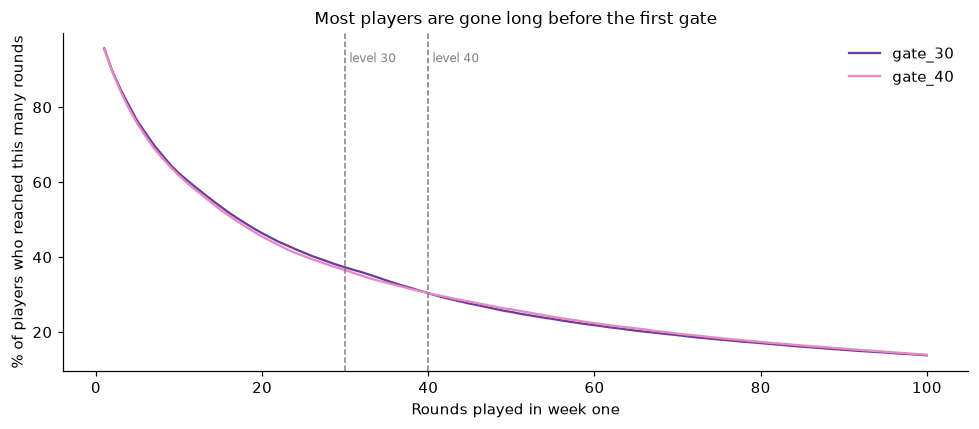

     gate_30  gate_40
1       95.7     95.5
5       76.3     75.6
10      62.3     61.7
20      46.4     45.5
30      37.3     36.5
40      30.3     30.4
60      21.8     22.4
100     13.8     14.0


In [6]:
k = np.arange(1, 101)
surv = pd.DataFrame({v: [(d.sum_gamerounds >= i).mean() for i in k] for v, d in [("gate_30", a), ("gate_40", b)]}, index=k)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(surv.index, 100 * surv.gate_30, color=PURPLE, label="gate_30"); ax.plot(surv.index, 100 * surv.gate_40, color=PINK, label="gate_40")
for lvl in (30, 40): ax.axvline(lvl, color="grey", ls="--", lw=1); ax.text(lvl + 0.5, 92, f"level {lvl}", fontsize=8, color="grey")
ax.set_xlabel("Rounds played in week one"); ax.set_ylabel("% of players who reached this many rounds")
ax.set_title("Most players are gone long before the first gate", fontsize=11); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG + "player_dropoff.png"); plt.show()
print(surv.loc[[1, 5, 10, 20, 30, 40, 60, 100]].mul(100).round(1).to_string())

Drop-off is steepest in the first rounds: 4.4% of players never play a round, about 16% play 2 or fewer, and half play 16 or fewer in the week. Only about a third of players ever reach level 30. The first gate therefore affects a minority of players, and any effect of moving it is **diluted** in the full-sample numbers below.

### Reaching the gate

In [7]:
tab = pd.DataFrame({
    "gate_30": {"reach 30+ rounds": (a.sum_gamerounds >= 30).mean(), "reach 40+ rounds": (a.sum_gamerounds >= 40).mean()},
    "gate_40": {"reach 30+ rounds": (b.sum_gamerounds >= 30).mean(), "reach 40+ rounds": (b.sum_gamerounds >= 40).mean()},
})
print((100 * tab).round(1).to_string())
for lvl in (30, 40):
    x, y = a[a.sum_gamerounds >= lvl].retention_7, b[b.sum_gamerounds >= lvl].retention_7
    print(f"\n7-day retention among players with {lvl}+ rounds: gate_30 {x.mean():.1%} (n={len(x):,}) vs gate_40 {y.mean():.1%} (n={len(y):,})")

                  gate_30  gate_40
reach 30+ rounds     37.3     36.5
reach 40+ rounds     30.3     30.4

7-day retention among players with 30+ rounds: gate_30 43.9% (n=16,656) vs gate_40 43.0% (n=16,613)

7-day retention among players with 40+ rounds: gate_30 50.3% (n=13,566) vs gate_40 48.5% (n=13,827)


Players reach levels 30 and 40 at about the same rate in both versions, as expected from random assignment. Among players who play at least 30 or 40 rounds, `gate_30` players return at an equal or slightly higher rate (43.9% vs 43.0% at 30+; 50.3% vs 48.5% at 40+).
These engaged-player comparisons are **descriptive only**: they condition on behavior that happens after the gate version is assigned, so they cannot establish cause. The causal comparison is on all randomized players, below.

## 4. 1-day retention

In [8]:
r1 = ab.diff_in_props(b.retention_1, a.retention_1)
print(f"gate_30 {a.retention_1.mean():.2%} | gate_40 {b.retention_1.mean():.2%} | difference {100*r1['diff']:+.2f} pts, 95% CI [{100*r1['lo']:+.2f}, {100*r1['hi']:+.2f}], p = {r1['p']:.3f}")

gate_30 44.82% | gate_40 44.23% | difference -0.59 pts, 95% CI [-1.24, +0.06], p = 0.074


1-day retention is 0.6 points lower in `gate_40` but the interval includes zero (p = 0.07): **inconclusive**. The data neither show harm nor rule out a small one at day one.

## 5. 7-day retention

In [9]:
rows = []
for m in ["retention_1", "retention_7"]:
    r = ab.diff_in_props(b[m], a[m])
    rows.append(dict(metric=m, gate_30=a[m].mean(), gate_40=b[m].mean(), diff_pts=100 * r["diff"],
                     ci_lo_pts=100 * r["lo"], ci_hi_pts=100 * r["hi"], p=r["p"]))
res = pd.DataFrame(rows); res["p_holm"] = ab.holm(res.p.values)
res.round(4)

,metric,gate_30,gate_40,diff_pts,ci_lo_pts,ci_hi_pts,p,p_holm
0,retention_1,0.4482,0.4423,-0.5905,-1.2393,0.0582,0.0744,0.0744
1,retention_7,0.1902,0.1820,-0.8201,-1.3282,-0.3121,0.0016,0.0031


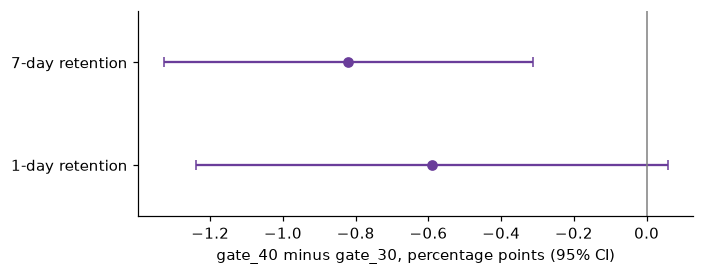

Bootstrap cross-check (10,000 resamples): -0.82 pts, 95% CI [-1.32, -0.32]


In [10]:
fig, ax = plt.subplots(figsize=(6.5, 2.6))
ax.errorbar(res.diff_pts, range(2), xerr=[res.diff_pts - res.ci_lo_pts, res.ci_hi_pts - res.diff_pts], fmt="o", color=PURPLE, capsize=3)
ax.axvline(0, color="grey", lw=1); ax.set_yticks(range(2), ["1-day retention", "7-day retention"]); ax.set_ylim(-0.5, 1.5)
ax.set_xlabel("gate_40 minus gate_30, percentage points (95% CI)"); plt.tight_layout(); plt.savefig(FIG + "retention_effect.png"); plt.show()
bt = ab.bootstrap_diff(b.retention_7, a.retention_7, n_boot=10000)
print(f"Bootstrap cross-check (10,000 resamples): {100*bt['diff']:+.2f} pts, 95% CI [{100*bt['lo']:+.2f}, {100*bt['hi']:+.2f}]")

**7-day retention falls by 0.82 points** (19.02% to 18.20%; 95% CI −1.33 to −0.31; Holm-corrected p = 0.003). The interval excludes zero, and a bootstrap gives the same interval. Plausible effects range from a 0.3-point to a 1.3-point drop.

### Does the conclusion survive the sample-ratio problem?

In [11]:
# Worst case for the finding: the ~395 'extra' gate_40 players are all 7-day non-returners.
# Removing them is the scenario that most helps gate_40.
excess = int(round((len(b) - len(a)) / 2))
kept = pd.concat([b[b.retention_7 == 1], b[b.retention_7 == 0].iloc[excess:]])
r = ab.diff_in_props(kept.retention_7, a.retention_7)
print(f"Dropping {excess} gate_40 non-returners: {100*r['diff']:+.2f} pts, 95% CI [{100*r['lo']:+.2f}, {100*r['hi']:+.2f}], p = {r['p']:.3f}")

Dropping 394 gate_40 non-returners: -0.66 pts, 95% CI [-1.17, -0.15], p = 0.011


Even in the scenario most favorable to `gate_40`, 7-day retention is still lower (about −0.66 points) with an interval that excludes zero. The *direction* is robust to the imbalance; the *size* is less certain.

### Was the test large enough?

In [12]:
n = ab.n_per_arm(0.19, 0.008)
print(f"Players per arm needed to detect a 0.8-point change in 7-day retention (80% power): {n:,} | actual: {len(a):,} and {len(b):,}")

Players per arm needed to detect a 0.8-point change in 7-day retention (80% power): 38,349 | actual: 44,700 and 45,489


With about 45,000 players per arm, the test could reliably detect changes of about 0.8 points in 7-day retention, which is the size found. It could not reliably detect a change that small in 1-day retention, which is why that result is inconclusive.

## 6. Recommendation, limits and next steps
**Keep the first gate at level 30.** Moving it to level 40 lowers 7-day retention by about 0.8 points (95% CI 0.3 to 1.3), and that holds in the worst case for the sample-ratio issue. Nothing in this data shows a retention benefit from the move. Because only about a third of players ever reach a gate, the effect on the players who do reach it is likely larger than the full-sample figure, though this data cannot estimate it cleanly.

**Limits**
- **No revenue.** A later gate could raise or lower in-app purchases; retention alone cannot settle the business question.
- **Sample-ratio mismatch (p = 0.009).** Find out why `gate_40` received 789 more players before acting.
- **Retention is a day-7 snapshot.** A player who returned on day 6 but not day 7 counts as lost; a retention curve would be more complete.
- **One game, one change, one test.**

**Next test.** Measure revenue per player and a retention curve (days 1 to 14) for the same two designs, with the assignment mechanism checked before launch.